# Chapitre 11 - Cours 6 : raisonner sur le temps

« La moyenne des cinq dernières minutes » : l'expression paraît limpide. Elle est en
réalité piégeuse dès que les événements arrivent en retard, dans le désordre, ou
horodatés par des horloges peu fiables. Ce notebook couvre la sous-section *Reasoning
About Time* : *Event time versus processing time*, *Knowing when you're ready*, *Whose clock
are you using, anyway?* et *Types of windows*. Les fonctions de fenêtrage et le compteur
à filigrane sont dans [`ddia/streams.py`](../../ddia/streams.py).

**Plan.**

1. Temps de l'événement contre temps de traitement.
2. Les retardataires : quand une fenêtre est-elle complète ? (filigranes)
3. L'horloge de qui ?
4. Les types de fenêtres.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

from ddia import streams as st
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Temps de l'événement contre temps de traitement (sections *Reasoning About Time* et *Event time versus processing time*)

Un traitement par lots traverse en quelques minutes une année d'événements historiques :
l'horloge de la machine qui l'exécute n'a aucun rapport avec l'époque des événements, il
utilise donc l'**horodatage contenu dans chaque événement**. Bonus : le traitement est
**déterministe**, le relancer sur la même entrée donne le même résultat.

Beaucoup de frameworks de flux utilisent au contraire l'horloge locale de la machine de
traitement, le **temps de traitement** (processing time), pour découper les fenêtres.
C'est simple, et raisonnable si le délai entre la création et le traitement d'un
événement est négligeable. Mais le traitement peut prendre du retard pour mille raisons :
files d'attente, pannes réseau, contention dans le courtier, redémarrage du consommateur,
retraitement du passé après une panne ou la correction d'un bogue. Les délais
**réordonnent** aussi les événements : un utilisateur fait une requête servie par le
serveur A, puis une autre servie par B ; si l'événement de B atteint le courtier avant
celui de A, les consommateurs les voient dans l'ordre inverse. (Le livre compare cela à
une saga cinématographique vue dans l'ordre de sortie des films, qui ne suit pas l'ordre
chronologique du récit : le numéro d'épisode est le temps de l'événement, la date de
visionnage le temps de traitement.)

Confondre les deux produit de **fausses données**. Un opérateur compte les requêtes par
seconde d'un service dont le débit réel est stable (200 par seconde en moyenne). On le
redéploie : il s'arrête une minute, puis rattrape son retard à cinq fois la vitesse
normale.

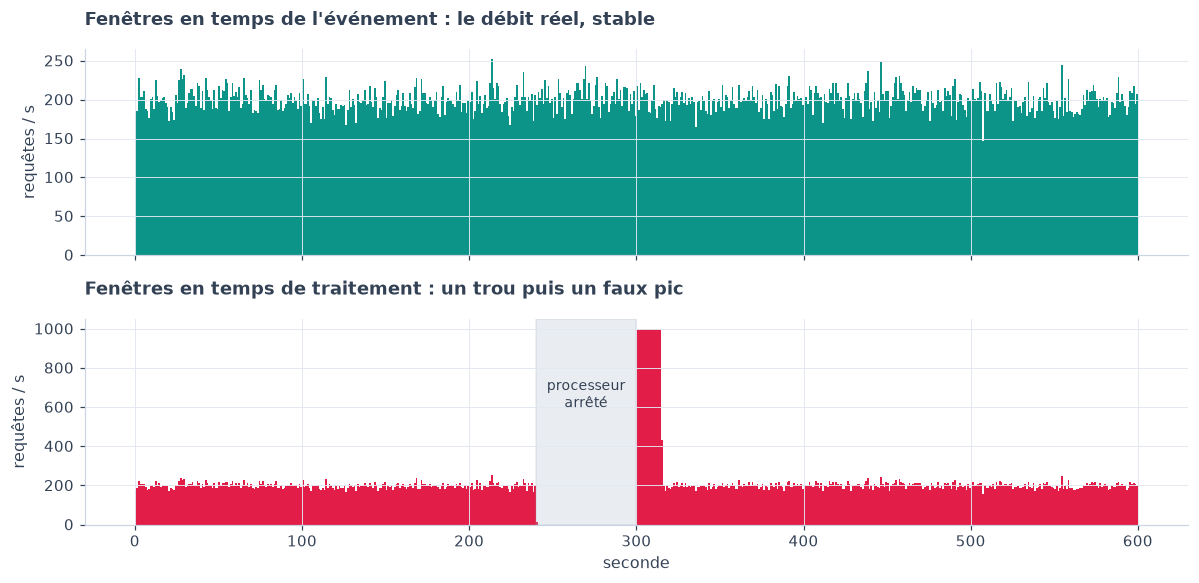

pic apparent en temps de traitement : 1000 req/s ; maximum réel : 252 req/s


In [2]:
T = 600
t_ev = np.sort(rng.uniform(0, T, 200 * T))
arret, reprise, vitesse = 240.0, 300.0, 5.0
# instant de traitement : les événements arrivés pendant l'arrêt attendent, puis la file se vide à 5x
t_tr = t_ev + 0.05
apres = t_ev >= arret
k = np.arange(apres.sum())
t_tr[apres] = np.maximum(t_ev[apres] + 0.05, reprise + k / (200 * vitesse))   # file vidée à 1 000 req/s
bins = np.arange(0, T + 1, 1)
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True)
ax.hist(t_ev, bins=bins, color=TEAL)
ax.set_ylabel("requêtes / s"); ax.set_title("Fenêtres en temps de l'événement : le débit réel, stable")
ax2.hist(t_tr, bins=bins, color=ROSE)
ax2.axvspan(arret, reprise, color=GRAY, alpha=0.2)
ax2.text((arret + reprise) / 2, 600, "processeur\narrêté", ha="center", fontsize=9, color=SLATE)
ax2.set_ylabel("requêtes / s"); ax2.set_xlabel("seconde")
ax2.set_title("Fenêtres en temps de traitement : un trou puis un faux pic")
plt.tight_layout(); plt.show()
print(f"pic apparent en temps de traitement : {np.histogram(t_tr, bins)[0].max()} req/s ; "
      f"maximum réel : {np.histogram(t_ev, bins)[0].max()} req/s")

Le débit réel n'a jamais dépassé 250 requêtes par seconde ; en temps de traitement, on voit
une minute à zéro puis un pic à environ mille, deux artefacts du redéploiement. Les
fenêtres en temps de l'événement donnent la bonne réponse, et la même réponse à chaque
rejeu.

> **À retenir.** Le temps de traitement est simple mais dépend des aléas du pipeline ; le
> temps de l'événement décrit la réalité et rend le calcul déterministe. Dès qu'il peut y
> avoir du retard, il faut fenêtrer en temps de l'événement.

## 2. Les retardataires (section *Knowing when you're ready*)

En temps de l'événement, une difficulté apparaît : on ne sait **jamais** si l'on a reçu
tous les événements d'une fenêtre. On compte les requêtes de la 37e minute ; le temps a
passé, la plupart des événements reçus concernent maintenant les 38e et 39e minutes.
Quand déclarer la 37e minute terminée et émettre son compteur ? On peut attendre un
moment sans nouvel événement pour cette fenêtre, mais certains peuvent être retenus sur
une autre machine par une coupure réseau. Les **retardataires** (stragglers) qui arrivent
après la clôture laissent deux options :

- les **ignorer** (ils sont en principe peu nombreux), en comptant les événements écartés
  et en alertant si leur proportion grimpe ;
- publier une **correction**, la valeur mise à jour de la fenêtre, en retirant
  éventuellement la précédente.

Une heuristique courante est le **filigrane** (watermark) : un message qui affirme
« désormais, plus aucun événement antérieur à $t$ ». Ici, l'opérateur le calcule lui-même
comme « plus grand temps d'événement vu, moins une marge $L$ » (`st.WatermarkCounter`) :
une fenêtre est émise quand le filigrane dépasse sa fin. Plus la marge est grande, moins
il y a de retardataires écartés, mais plus le résultat arrive tard. Simulons 20 000
événements (10 par seconde, fenêtres de 10 s), avec un délai réseau log-normal de médiane
0,5 s et 1 % d'appareils hors ligne qui envoient leurs événements jusqu'à plusieurs
minutes plus tard.

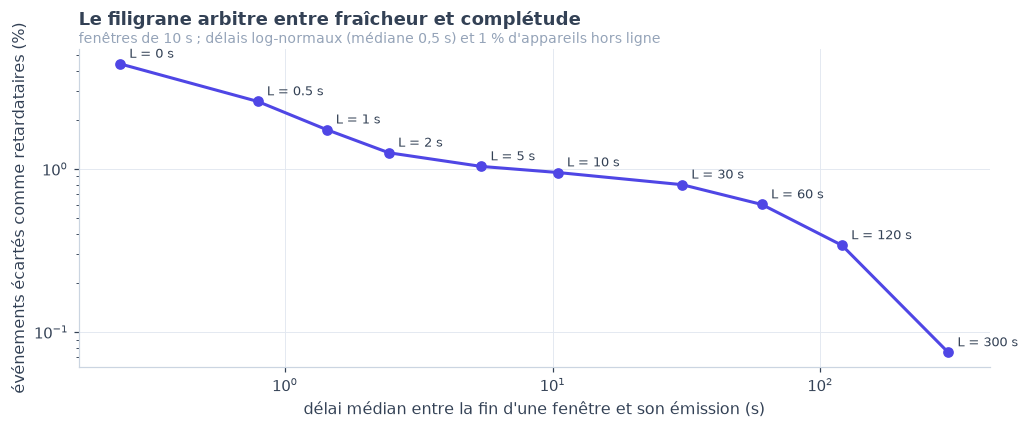

,écartés (%),délai médian d'émission (s),erreur moyenne par fenêtre,fenêtres ouvertes (max),corrections (politique update)
marge L (s),,,,,
0.0,4.40,0.45,4.40,1,880
0.5,2.59,0.91,2.59,2,518
1.0,1.74,1.43,1.74,2,348
2.0,1.26,2.44,1.25,2,251
5.0,1.03,5.41,1.03,2,207
10.0,0.95,10.45,0.95,2,190
30.0,0.80,30.45,0.80,4,160
60.0,0.60,60.45,0.60,7,121
120.0,0.34,120.46,0.34,13,68


In [3]:
n = 20_000
et = np.sort(rng.uniform(0, 2000, n))
delai = rng.lognormal(np.log(0.5), 0.8, n)
hors_ligne = rng.random(n) < 0.01
delai[hors_ligne] += rng.exponential(120, hors_ligne.sum())
arr = et + delai
vrai = st.tumbling_counts(et, 10)
rows = []
for L in [0, 0.5, 1, 2, 5, 10, 30, 60, 120, 300]:
    wc = st.WatermarkCounter(10, lateness=L, policy="drop").run(et, arr)
    finals = [r for r in wc.results if r.kind == "final"]
    lat = np.array([r.emitted_at - (r.window + 10) for r in finals])
    err = np.mean([abs(r.count - vrai[r.window]) for r in finals])
    wu = st.WatermarkCounter(10, lateness=L, policy="update").run(et, arr)
    rows.append({"marge L (s)": L, "écartés (%)": wc.dropped / n * 100, "délai médian d'émission (s)": np.median(lat),
                 "erreur moyenne par fenêtre": err, "fenêtres ouvertes (max)": wc.max_open,
                 "corrections (politique update)": sum(r.kind == "correction" for r in wu.results)})
W = pd.DataFrame(rows).set_index("marge L (s)")
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.plot(W["délai médian d'émission (s)"], W["écartés (%)"], "o-", color=INDIGO)
for L, r in W.iterrows():
    ax.annotate(f"L = {L:g} s", (r["délai médian d'émission (s)"], r["écartés (%)"]), (6, 4),
                textcoords="offset points", fontsize=8.5, color=SLATE)
ax.set_xscale("symlog", linthresh=1); ax.set_yscale("log")
ax.set_xlabel("délai médian entre la fin d'une fenêtre et son émission (s)")
ax.set_ylabel("événements écartés comme retardataires (%)")
ax.set_title("Le filigrane arbitre entre fraîcheur et complétude")
subtitle(ax, "fenêtres de 10 s ; délais log-normaux (médiane 0,5 s) et 1 % d'appareils hors ligne")
plt.tight_layout(); plt.show()
W.round(2)

Sans marge, 4,4 % des événements arrivent après la clôture de leur fenêtre : ce sont
surtout ceux des dernières secondes de chaque fenêtre, doublés par un événement plus
récent qui a fait avancer le filigrane. Le résultat est immédiat mais faux. Une marge
de quelques secondes absorbe le délai réseau ordinaire et ramène les pertes au voisinage
du 1 % d'appareils hors ligne ; pour récupérer ces derniers, il faut attendre plusieurs
minutes, et garder d'autant plus de fenêtres ouvertes en mémoire. La politique
« correction » évite de choisir : on émet tôt, puis on corrige (le nombre de corrections
décroît avec la marge), au prix de consommateurs capables de gérer des mises à jour.

**Plusieurs producteurs.** Si chaque producteur publie son propre filigrane, le
consommateur doit suivre chacun séparément et ne peut avancer qu'au **minimum** des
filigranes. Un producteur silencieux (en pause, en panne, ou simplement inactif) bloque
alors l'émission de toutes les fenêtres, et ajouter ou retirer des producteurs complique
encore la gestion.

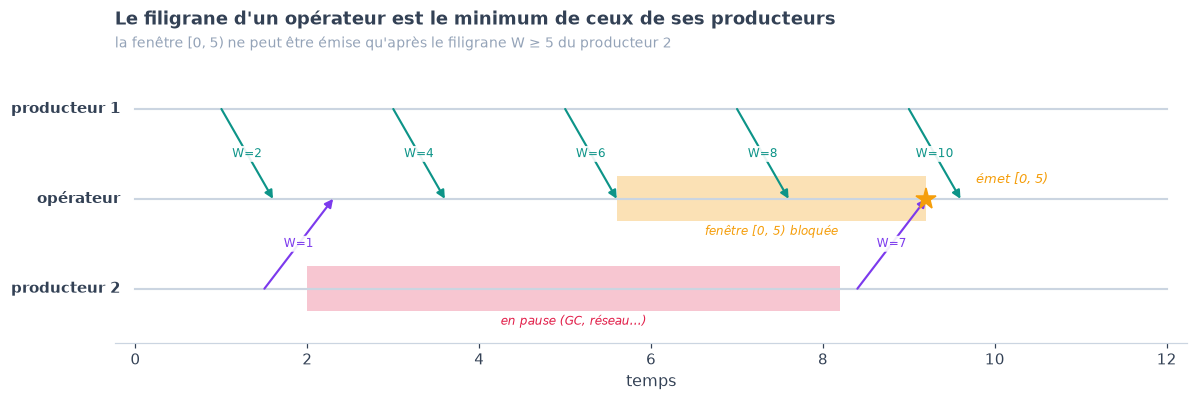

In [4]:
stt = SpaceTime(["producteur 1", "opérateur", "producteur 2"], t_max=12, width=11,
                title="Le filigrane d'un opérateur est le minimum de ceux de ses producteurs",
                subtitle="la fenêtre [0, 5) ne peut être émise qu'après le filigrane W ≥ 5 du producteur 2")
for t, w in [(1.0, 2), (3.0, 4), (5.0, 6), (7.0, 8), (9.0, 10)]:
    stt.msg("producteur 1", t, "opérateur", t + 0.6, f"W={w}", color=TEAL)
stt.msg("producteur 2", 1.5, "opérateur", 2.3, "W=1", color=VIOLET)
stt.span("producteur 2", 2.0, 8.2, "en pause (GC, réseau...)", color=ROSE, alpha=0.25)
stt.msg("producteur 2", 8.4, "opérateur", 9.2, "W=7", color=VIOLET)
stt.span("opérateur", 5.6, 9.2, "fenêtre [0, 5) bloquée", color=AMBER, alpha=0.3)
stt.event("opérateur", 9.2, "", kind="star")
stt.note(10.2, "opérateur", "émet [0, 5)", dy=0.22, color=AMBER)
stt.show()

> **À retenir.** On ne sait jamais si une fenêtre en temps de l'événement est complète.
> Un filigrane parie qu'elle l'est ; sa marge règle le compromis entre fraîcheur,
> complétude et mémoire. Les retardataires sont écartés (et comptés) ou donnent lieu à des
> corrections.